# OVCA leave-one-cell-type-out: **label transfer vs embedding transfer**

Two models predict the same thing — the expression a `Smooth muscle` cell would have if it were
placed in `Tumor` tissue — and differ in exactly one respect: how they are told "you are now in
Tumor".

| | conditioning vector | dims |
|---|---|---|
| **labels** (`wsi.LabelsBaseline`) | `[onehot(cell_type), onehot(domain)]` | 7 + 5 |
| **embeddings** (`wsi.EmbeddingsBaseline`) | `[onehot(cell_type), virchow2]` | 7 + 2560 |

Everything else is shared: the same `DecoderSCVI`, NB likelihood, observed library size, no
encoder, the same hyperparameters (`configs/labels_config.py` == `configs/embeddings_config.py`
by design), the same split, the same arms, the same metrics. So a gap in the table is
attributable to the domain representation — a 5-way categorical *word* versus a continuous H&E
foundation-model vector — and to nothing else.

The Virchow2 vectors are the per-cell 112um H&E tile embeddings from
[`05_roi_embedding_classifiers.ipynb`](05_roi_embedding_classifiers.ipynb), carried in the LOO
bundle as `obsm["virchow2"]` (14,170 x 2560).

### What changed from the previous version of this notebook

The committed predecessor (`git show e9ac027`) compared `cellina` against the labels baseline on
**WSI-predicted** domains. Three things are gone:

- **`cellina`** — dropped entirely, along with `preprocess_spatial_features`; neither remaining
  model uses the spatial neighbour graph.
- **`pred_domain`** — dropped entirely. The 05 logistic regression plays no part here; we use its
  *embeddings*, not its predictions. (It would also have been a no-op: in the four scored ROIs
  `pred_domain == domain` for 2,244 / 2,244 cells, because those ROIs are in 05's own training
  set.)
- **The cell-level split** — replaced by an ROI-level one, see below. This is not optional for a
  model conditioned on H&E tiles.

## The split has to be ROI-level

`split_indices` holds out *cells*. That is safe for a model that sees only counts and labels, but
it leaks badly for anything conditioned on per-cell H&E tiles: tiles are ~112um wide while cells
sit 7-9um apart, so **neighbouring cells' tiles overlap by >90%**. Holding out a Stromal cell
while training on the Malignant cell beside it hands the model that Stromal cell's pixels anyway.

So `eval.split_indices_roi_holdout` withholds **both**:

- **every cell in Tumor ROIs `[9, 6, 3, 8]`** — closes the pixel leak, and
- **every `(Stromal, Tumor)` cell slide-wide** — preserves the leave-one-cell-type-out property.

Those four ROIs are the Tumor ROIs richest in Stromal cells (181/134/129/116 = 560, versus 13 for
the worst pair). That is a **statistical-power** choice, made on cell abundance and never on any
model's score — so it cannot favour one model over the other — but it does narrow the OOD claim
to stroma-rich tumour regions.

## Arms, and what "donor" means

- **control arm** — all 2,803 `Smooth muscle` cells. These stay in training: they are the
  counterfactual's *input*, not its target, so there is nothing to protect.
- **observed target arm** — the 2,244 real Tumor cells inside the withheld ROIs
  (`obs["is_scored_target"]`). Their measured Xenium counts are the answer the predictions are
  scored against. Both models are pixel-blind *and* expression-blind to these cells.

The labels model's counterfactual is a one-line relabel: flip the domain one-hot to `Tumor`.
The embeddings model has no `Tumor` token — it was trained with 2,560 real numbers in that slot —
so "you are now in Tumor" has to be an actual vector. Each control cell is therefore handed a
**donor**: a real Tumor cell's Virchow2 vector, and nothing else about that cell (no expression,
no labels). Two donor pools are reported, because the choice changes what the number means:

| row | donor pool | what it tests |
|---|---|---|
| `embeddings (donor: other 8 ROIs)` | 5,411 non-Stromal Tumor cells in ROIs 1,2,4,5,7,10,11,12 | does a 2560-d vector beat the word "Tumor"? — no contact with the scored region at all |
| `embeddings (donor: ROIs 3/6/8/9)` | 1,684 non-Stromal Tumor cells inside the scored ROIs | does it matter *which* tumour the H&E came from? — same donor design cellina gets in `03_loo_eval_path2space.ipynb` |

Stromal cells never donate, in either pool, so the held-out cell type never re-enters through the
back door. Note that the second pool *is* the ID-scored population: the model reads those cells'
H&E appearance (never their expression).

## The ceiling row

`embeddings (own tile)` is **not** a counterfactual and must never be quoted as one. It feeds each
of the 2,244 real Tumor cells its *own* tile and its own cell type and predicts its expression, so
it reads the H&E of the very cells being scored. It is a ceiling that answers a prior question: is
the tumour expression signal in Virchow2 H&E at all? If the ceiling is high and the counterfactual
rows are low, transfer is the bottleneck; if the ceiling is also low, H&E simply does not carry
this signal. The `kind` column keeps this distinction attached to the numbers.

## Read this before interpreting the ID row

The two regimes are **not** equally sound. They slice the same one-pass predictions by cell type:

- **OOD** — the held-out type. 2,538 predicted Stromal cells (the control arm is 91% Stromal)
  against 560 observed Stromal cells. Well powered, and `(Stromal, Tumor)` was never trained on.
  **This is the row that carries the result.**
- **ID** — the held-in types. Only 265 predicted cells (179 Endothelial, 42 Malignant, 28
  Myeloid, 16 Lymphoid) against 1,684 observed ones (1,346 Malignant, 125 Myeloid, 108 Pericytes,
  59 Endothelial, 42 Lymphoid, 4 Epithelial). The metrics compare arm *means*, so ID is partly
  measuring a **cell-type composition mismatch** — mostly-Endothelial predictions against a
  mostly-Malignant target, with zero Pericytes or Epithelial on the predicted side against 112 on
  the observed side. It is kept for continuity with `03_loo_eval.ipynb`; do not read it as a
  clean in-distribution control.

## Replication

Both models are retrained under **seeds 0/1/2** with a fresh donor draw each time, and section C
reports **mean ± sd**. On 560 OOD cells a pearson gap of a few hundredths is otherwise
indistinguishable from initialisation luck.

## How to run

```bash
# once, in lazyslide-env -> writes data/ovca_loo/ (needs zarr 3 for OVCA_with_embeddings.zarr)
/g/stegle/spiljak/programs/miniforge3/envs/lazyslide-env/bin/python scripts/prepare_ovca_loo_data.py
```

Then run this notebook top to bottom in the **`cellina_edge`** kernel (it has scvi + torch +
sklearn; `lazyslide-env` has no scvi). Section C needs only the cached predictions, so it can be
re-run in a fresh kernel.

Models, per-cell predictions and per-seed metrics are written to **`/scratch`** — `/g/stegle` has
under 10 GB free and this run produces ~1.3 GB.

## A. Setup — data, split, arms, donor pools  *(`cellina_edge` kernel)*

In [1]:
import os
import sys

import numpy as np
import pandas as pd

# ../scripts for the LOO plumbing (eval/metrics); ../src for the `wsi` package (LabelsBaseline,
# EmbeddingsBaseline), which is not pip-installed into cellina_edge.
# Resolved from PROJECT_ROOT rather than a relative "../" path: kernel cwd is not reliably the
# notebook's own directory when connecting to an existing Jupyter server (e.g. from VS Code).
PROJECT_ROOT = "/g/stegle/spiljak/projects/main_wsi_ood"
sys.path.append(os.path.join(PROJECT_ROOT, "scripts"))
sys.path.append(os.path.join(PROJECT_ROOT, "src"))

from utils import set_seed
from eval import (
    load_ovca_loo_bundle,
    preprocess_ovca,
    split_indices_roi_holdout,   # ROI-level: the only leakage-safe split for tile-conditioned models
    make_comparison_adata,
    run_loo_eval,
    COUNTS_PER_K,
)
from configs.adata_ovca_config import ADATA_ARGS
from configs.embeddings_config import EMBEDDING_KEY, SCALED_EMBEDDING_KEY, SEEDS

# --- experiment config (see configs/adata_ovca_config.py) -------------------
# Bundle built by scripts/prepare_ovca_loo_data.py under lazyslide-env -- see its header for why
# this notebook cannot read OVCA_with_embeddings.zarr directly (zarr v3 / Arrow strings).
BUNDLE_DIR = os.path.join(PROJECT_ROOT, "data/ovca_loo")

LABELS_KEY = ADATA_ARGS["labels_key"]             # "cell_type"     always ground truth
DOMAINS_KEY = ADATA_ARGS["domains_key"]           # "domain"        ground truth throughout
HOLDOUT_CT = ADATA_ARGS["holdout_celltype"]       # "Stromal"
CONTROL_LABEL = ADATA_ARGS["control_domains"][0]  # "Smooth muscle" (quiescent stroma)
HOLDOUT_LABEL = ADATA_ARGS["holdout_domains"][0]  # "Tumor"
HOLDOUT_ROIS = ADATA_ARGS["holdout_rois"]         # [9, 6, 3, 8] -- whole Tumor ROIs withheld

PERT_COL = "domain_arm"   # 2-level arm label on the comparison AnnDatas

# /g/stegle is >99% full and this run writes ~1.3 GB of predictions, so artifacts live on
# /scratch (same pattern as the datasets -- see scripts/integrate_roi_into_zarr.py).
PRED_DIR = "/scratch/spiljak/wsi_ood_preds/ovca_labels_vs_embed"
MODEL_DIR = os.path.join(PRED_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

# Registry of what section C scores. `kind` travels with the numbers so the ceiling can never be
# mistaken for a peer once the table is copied out of the notebook.
MODELS = {
    "labels":      ("labels",                            "counterfactual"),
    "emb_other":   ("embeddings (donor: other 8 ROIs)",  "counterfactual"),
    "emb_region":  ("embeddings (donor: ROIs 3/6/8/9)",  "counterfactual"),
    "emb_ceiling": ("embeddings (own tile)",             "direct - CEILING"),
}

print(f"{CONTROL_LABEL!r} -> {HOLDOUT_LABEL!r}, holding out {HOLDOUT_CT!r}")
print(f"withheld ROIs: {HOLDOUT_ROIS}   seeds: {SEEDS}   ->  {PRED_DIR}")

'Smooth muscle' -> 'Tumor', holding out 'Stromal'
withheld ROIs: [9, 6, 3, 8]   seeds: [0, 1, 2]   ->  /scratch/spiljak/wsi_ood_preds/ovca_labels_vs_embed


In [2]:
# Load the prepared bundle (raw counts + micron centroids + uni2/virchow2 per-cell H&E
# embeddings), then the shared QC. n_top_genes=None: the Xenium panel is already curated, so no
# HVG subsetting. No spatial-feature step -- cellina is gone and neither model uses the graph.
adata = load_ovca_loo_bundle(BUNDLE_DIR)
adata = preprocess_ovca(
    adata,
    n_top_genes=ADATA_ARGS["n_top_genes"],
    labels_key=LABELS_KEY,
    domains_key=DOMAINS_KEY,
    pred_domains_key=ADATA_ARGS["pred_domains_key"],  # carried as a column, never used
)
print(adata)
print(f"\n{EMBEDDING_KEY}: {adata.obsm[EMBEDDING_KEY].shape}")

# Expect 14170 x 5090 (filter_genes drops 11 of the 5101; no cells dropped), virchow2 (14170, 2560)

/g/stegle/spiljak/projects/main_wsi_ood/scripts/eval.py:71: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[labels_key] = adata.obs[labels_key].astype("category")


AnnData object with n_obs × n_vars = 14170 × 5090
    obs: 'cell_id', 'cell_type', 'domain', 'pred_domain', 'roi_id', 'roi_domain', 'split_05', 'n_counts'
    var: 'n_counts'
    obsm: 'spatial', 'uni2', 'virchow2'
    layers: 'counts'

virchow2: (14170, 2560)


In [ ]:
# ROI-level leave-one-cell-type-out split: withhold all cells in Tumor ROIs [9,6,3,8] AND every
# (Stromal, Tumor) cell slide-wide. Sets obs["is_scored_target"] = the Tumor cells inside those
# ROIs, which is what section C scores.
train_idx, val_idx, test_idx = split_indices_roi_holdout(
    adata, HOLDOUT_CT, HOLDOUT_ROIS,
    labels_key=LABELS_KEY, domains_key=DOMAINS_KEY,
    holdout_domains=ADATA_ARGS["holdout_domains"], seed=0,
)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")
print(f"scored target cells: {int(adata.obs['is_scored_target'].sum())}")

# Expect train=10408  val=1156  test=2606   scored target=2244

train=10408  val=1156  test=2606
scored target cells: 2244


In [4]:
# Scale the H&E embedding. DecoderSCVI's first layer is a plain Linear (batch-norm is applied
# after the multiply, not to the input), and Virchow2's per-feature std spans 0.027 to 16, so
# unscaled features would enter with a 600x scale spread. The scaler is fit on TRAINING CELLS
# ONLY, so the withheld ROIs do not even influence the standardisation.
from joblib import dump
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(np.asarray(adata.obsm[EMBEDDING_KEY])[train_idx])
adata.obsm[SCALED_EMBEDDING_KEY] = np.ascontiguousarray(
    scaler.transform(np.asarray(adata.obsm[EMBEDDING_KEY])).astype(np.float32)
)
dump(scaler, os.path.join(MODEL_DIR, f"{EMBEDDING_KEY}_scaler.joblib"))

x = adata.obsm[SCALED_EMBEDDING_KEY]
print(f"{SCALED_EMBEDDING_KEY}: {x.shape}  mean={x.mean():.3f}  std={x.std():.3f}  "
      f"(fit on {len(train_idx)} training cells)")

virchow2_scaled: (14170, 2560)  mean=-0.000  std=0.994  (fit on 10408 training cells)


In [ ]:
# --- Arms -------------------------------------------------------------------------------------
# control = ALL Smooth-muscle cells (inputs to the counterfactual, deliberately kept in training)
# target  = the Tumor cells inside the withheld ROIs (never seen: not their expression, not their
#           pixels). Their measured counts are what every prediction is scored against.
mask_control = (adata.obs[DOMAINS_KEY].astype(str) == CONTROL_LABEL).values
mask_target = adata.obs["is_scored_target"].values
idx_control = np.where(mask_control)[0]
idx_target = np.where(mask_target)[0]

# Cell type per arm, attached to every comparison AnnData so section C can slice OOD from ID.
# The counterfactual moves control cells into Tumor but each keeps its own type, so a predicted
# counterfactual arm carries the CONTROL cells' types.
ct_control = adata.obs[LABELS_KEY].astype(str).values[mask_control]
ct_target = adata.obs[LABELS_KEY].astype(str).values[mask_target]

# --- Donor pools for the embeddings counterfactual ---------------------------------------------
# A donor lends its Virchow2 vector and nothing else. Stromal is excluded from BOTH pools so the
# held-out cell type never re-enters. See the header for what each pool tests.
is_tumor = (adata.obs[DOMAINS_KEY].astype(str) == HOLDOUT_LABEL).values
is_holdout_ct = (adata.obs[LABELS_KEY].astype(str) == HOLDOUT_CT).values
in_holdout_roi = adata.obs["roi_id"].isin(HOLDOUT_ROIS).values

DONOR_POOLS = {
    "emb_other": np.where(is_tumor & ~in_holdout_roi & ~is_holdout_ct)[0],
    "emb_region": np.where(is_tumor & in_holdout_roi & ~is_holdout_ct)[0],
}

print(f"control({CONTROL_LABEL}) = {idx_control.size}    target({HOLDOUT_LABEL}, withheld ROIs) = {idx_target.size}")
for name, pool in DONOR_POOLS.items():
    print(f"  donor pool {name:11s} = {pool.size:5d} cells   (Stromal excluded)")

print("\ncell types, predicted arm (control) vs observed target arm:")
print(pd.concat(
    {"predicted (control cells)": pd.Series(ct_control).value_counts(),
     "observed (target cells)": pd.Series(ct_target).value_counts()},
    axis=1,
).fillna(0).astype(int).to_string())
print("\n^ the ID regime compares the non-Stromal rows of these two columns against each other;")
print("  see the composition caveat in the header before reading the ID numbers.")

control(Smooth muscle) = 2803    target(Tumor, withheld ROIs) = 2244
  donor pool emb_other   =  5411 cells   (Stromal excluded)
  donor pool emb_region  =  1684 cells   (Stromal excluded)

cell types, predicted arm (control) vs observed target arm:
             predicted (control cells)  observed (target cells)
Stromal                           2538                      560
Endothelial                        179                       59
Malignant                           42                     1346
Myeloid                             28                      125
Lymphoid                            16                       42
Pericytes                            0                      108
Epithelial                           0                        4

^ the ID regime compares the non-Stromal rows of these two columns against each other;
  see the composition caveat in the header before reading the ID numbers.


In [6]:
# Observed pair (ground truth): real control counts vs real target counts, with the cell-type
# label attached so section C can slice OOD (held-out type) from ID (held-in types).
import anndata as ad
ad.settings.allow_write_nullable_strings = True

observed = make_comparison_adata(
    adata.layers["counts"][mask_control, :],
    adata.layers["counts"][mask_target, :],
    adata.var_names, control_label=CONTROL_LABEL, perturbed_label=HOLDOUT_LABEL,
    pert_col=PERT_COL,
)
observed.obs[LABELS_KEY] = np.concatenate([ct_control, ct_target])
observed.write(os.path.join(PRED_DIR, "observed.h5ad"))
observed

# Expect 5047 x 5090  (2803 control + 2244 target)

AnnData object with n_obs × n_vars = 5047 × 5090
    obs: 'domain_arm', 'cell_type'

## B. Train both models, 3 seeds  *(same kernel)*

One loop, one shared `adata`, one shared split. Per seed: train `LabelsBaseline`, run its
counterfactual, then train `EmbeddingsBaseline` and run its three inference passes (two donor
pools + the own-tile ceiling). The embeddings model is trained **once** per seed — the two donor
rows are the same trained network queried with different conditioning vectors, not two models.

Each trained model is saved under `models/`, and every prediction is written as a full per-cell
`.h5ad`, so section C (and any later metric) needs no retraining.

Order matters inside the loop: `setup_anndata` re-registers the shared `adata`, so all inference
for one model is finished before the next one is set up.

In [8]:
import scvi
from wsi.labels_baseline import LabelsBaseline
from wsi.embeddings_baseline import EmbeddingsBaseline
from configs.labels_config import (
    MODEL_ARGS as LABELS_MODEL_ARGS,
    TRAIN_ARGS as LABELS_TRAIN_ARGS,
    PLAN_KWARGS as LABELS_PLAN_KWARGS,
)
from configs.embeddings_config import (
    MODEL_ARGS as EMB_MODEL_ARGS,
    TRAIN_ARGS as EMB_TRAIN_ARGS,
    PLAN_KWARGS as EMB_PLAN_KWARGS,
)


def _train_args(base):
    """Same split for every model, every seed."""
    a = dict(base)
    a["datasplitter_kwargs"] = {"external_indexing": [train_idx, val_idx, test_idx]}
    return a


def save_pred(key, seed, control_arm, perturbed_arm, ct_perturbed):
    """Write a model's (control reconstruction, prediction) pair as a scoreable AnnData."""
    pred = make_comparison_adata(
        control_arm, perturbed_arm, adata.var_names,
        control_label=CONTROL_LABEL, perturbed_label=HOLDOUT_LABEL, pert_col=PERT_COL,
    )
    pred.obs[LABELS_KEY] = np.concatenate([ct_control, ct_perturbed])
    path = os.path.join(PRED_DIR, f"{key}_seed{seed}.h5ad")
    pred.write(path)
    print(f"    -> {os.path.basename(path)}  {pred.shape}")
    return pred


for seed in SEEDS:
    print(f"\n{'=' * 70}\nSEED {seed}\n{'=' * 70}")
    set_seed(seed)
    scvi.settings.seed = seed

    # ---------- labels baseline: domain as a 5-way one-hot ------------------------------------
    LabelsBaseline.setup_anndata(
        adata, labels_key=LABELS_KEY, domains_key=DOMAINS_KEY,
        batch_key=ADATA_ARGS["batch_key"], layer="counts",
    )
    labels_model = LabelsBaseline(adata, **LABELS_MODEL_ARGS)
    labels_model.train(**_train_args(LABELS_TRAIN_ARGS), plan_kwargs=LABELS_PLAN_KWARGS)
    labels_model.save(os.path.join(MODEL_DIR, f"labels_seed{seed}"), overwrite=True)

    # counterfactual = relabel the control cells' domain to Tumor and decode
    labels_ctrl = labels_model.get_normalized_expression(
        adata[mask_control], library_size=COUNTS_PER_K, batch_size=2048,
    )
    labels_cf = labels_model.get_counterfactual_expression(
        idx_control, target_domain=HOLDOUT_LABEL, batch_size=2048,
    )
    save_pred("labels", seed, labels_ctrl, labels_cf, ct_control)

    # ---------- embeddings baseline: domain as a 2560-d Virchow2 vector ------------------------
    EmbeddingsBaseline.setup_anndata(
        adata, labels_key=LABELS_KEY, embedding_obsm_key=SCALED_EMBEDDING_KEY,
        batch_key=ADATA_ARGS["batch_key"], layer="counts",
    )
    emb_model = EmbeddingsBaseline(adata, **EMB_MODEL_ARGS)
    emb_model.train(**_train_args(EMB_TRAIN_ARGS), plan_kwargs=EMB_PLAN_KWARGS)
    emb_model.save(os.path.join(MODEL_DIR, f"embeddings_seed{seed}"), overwrite=True)

    # control reconstruction: each control cell decoded from its OWN tile
    emb_ctrl = emb_model.get_normalized_expression(
        adata[mask_control], library_size=COUNTS_PER_K, batch_size=2048,
    )

    # counterfactual = hand each control cell a real Tumor cell's H&E vector. One draw per seed,
    # with replacement; the donor indices are persisted so any row can be reproduced exactly.
    rng = np.random.default_rng(seed)
    for key, pool in DONOR_POOLS.items():
        donors = rng.choice(pool, size=idx_control.size, replace=True)
        np.save(os.path.join(PRED_DIR, f"donors_{key}_seed{seed}.npy"), donors)
        emb_cf = emb_model.get_counterfactual_expression(
            idx_control, donor_indices=donors, batch_size=2048,
        )
        save_pred(key, seed, emb_ctrl, emb_cf, ct_control)

    # CEILING (not a counterfactual): each real target cell decoded from its OWN tile and type.
    # The perturbed arm is therefore the target cells, so it carries ct_target.
    emb_direct = emb_model.get_normalized_expression(
        adata[mask_target], library_size="latent", batch_size=2048,
    )
    save_pred("emb_ceiling", seed, emb_ctrl, emb_direct, ct_target)

print("\nall seeds done")

/g/stegle/spiljak/programs/miniforge3/envs/lazyslide-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[rank: 0] Seed set to 0



SEED 0


/g/stegle/spiljak/programs/miniforge3/envs/lazyslide-env/lib/python3.11/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /g/stegle/spiljak/programs/miniforge3/envs/lazyslide ...
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/g/stegle/spiljak/programs/miniforge3/envs/lazyslide-env/lib/python3.11/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python

Epoch 100/100: 100%|██████████| 100/100 [01:00<00:00,  2.75it/s, v_num=1, train_loss=713]

`Trainer.fit` stopped: `max_epochs=100` reached.


...

Epoch 100/100: 100%|██████████| 100/100 [01:45<00:00,  1.05s/it, v_num=1, train_loss=712]
INFO     Received view of anndata, making copy.                                                                    
INFO     Input AnnData not setup with scvi-tools. attempting to transfer AnnData setup                             
INFO     AnnData object appears to be a copy. Attempting to transfer setup.                                        
    -> labels_seed2.h5ad  (5606, 5090)
INFO     Generating sequential column names                                                                        


/g/stegle/spiljak/programs/miniforge3/envs/lazyslide-env/lib/python3.11/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /g/stegle/spiljak/programs/miniforge3/envs/lazyslide ...
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/g/stegle/spiljak/programs/miniforge3/envs/lazyslide-env/lib/python3.11/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python

Epoch 100/100: 100%|██████████| 100/100 [01:29<00:00,  2.17it/s, v_num=1, train_loss=708]

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [01:29<00:00,  1.11it/s, v_num=1, train_loss=708]
INFO     Received view of anndata, making copy.                                                                    
INFO     Input AnnData not setup with scvi-tools. attempting to transfer AnnData setup                             
INFO     AnnData object appears to be a copy. Attempting to transfer setup.                                        
    -> emb_other_seed2.h5ad  (5606, 5090)
INFO     AnnData object appears to be a copy. Attempting to transfer setup.                                        
    -> emb_region_seed2.h5ad  (5606, 5090)
INFO     Received view of anndata, making copy.                                                                    
INFO     Input AnnData not setup with scvi-tools. attempting to transfer AnnData setup                             
    -> emb_ceiling_seed2.h5ad  (5047, 5090)

all seeds done


## C. Compare — OOD + ID, mean ± sd over seeds

Each cached prediction is scored with `compare_adatas` on the top-50 observed-effect genes,
sliced by cell type into the two regimes. `run_loo_eval` uses
`predicted_logfc_baseline="observed_control"`, so both the observed and the predicted logFC are
measured against the *same observed* control population within each regime — which also means the
predicted control arm is not read by this table at all (only the figure uses it).

Metrics: `pearson_logfc` and `precision_at_top_n` are higher-is-better; `rmse_logfc` and
`edistance_pca` are lower-is-better; `spearman_avg` is higher-is-better.

In [9]:
import os, sys
import numpy as np
import pandas as pd
import scanpy as sc

sys.path.append("/g/stegle/spiljak/projects/main_wsi_ood/scripts")
from eval import run_loo_eval
from metrics import get_perturbation_effects

# Re-declared so section C runs standalone in a fresh kernel.
PRED_DIR = "/scratch/spiljak/wsi_ood_preds/ovca_labels_vs_embed"
PERT_COL, LABELS_KEY = "domain_arm", "cell_type"
CONTROL_LABEL, HOLDOUT_LABEL, HOLDOUT_CT = "Smooth muscle", "Tumor", "Stromal"
SEEDS = [0, 1, 2]
MODELS = {
    "labels":      ("labels",                            "counterfactual"),
    "emb_other":   ("embeddings (donor: other 8 ROIs)",  "counterfactual"),
    "emb_region":  ("embeddings (donor: ROIs 3/6/8/9)",  "counterfactual"),
    "emb_ceiling": ("embeddings (own tile)",             "direct - CEILING"),
}
REGIMES = {
    "OOD": lambda a: (a.obs[LABELS_KEY].astype(str) == HOLDOUT_CT).values,
    "ID": lambda a: (a.obs[LABELS_KEY].astype(str) != HOLDOUT_CT).values,
}

observed = sc.read(os.path.join(PRED_DIR, "observed.h5ad"))

rows = []
for seed in SEEDS:
    for key, (display, kind) in MODELS.items():
        pred = sc.read(os.path.join(PRED_DIR, f"{key}_seed{seed}.h5ad"))
        for regime, mask_fn in REGIMES.items():
            o = observed[mask_fn(observed)].copy()
            p = pred[mask_fn(pred)].copy()
            r = run_loo_eval(o, p, pert_col=PERT_COL, control_label=CONTROL_LABEL).iloc[0]
            rows.append({"regime": regime, "model": display, "kind": kind, "seed": seed,
                         "n_observed": int(mask_fn(observed).sum() - (o.obs[PERT_COL] == CONTROL_LABEL).sum()),
                         **r.to_dict()})

per_seed = pd.DataFrame(rows)
per_seed.to_csv(os.path.join(PRED_DIR, "metrics_per_seed.csv"), index=False)
print(f"per-seed metrics ({len(per_seed)} rows) -> {PRED_DIR}/metrics_per_seed.csv")
per_seed.head()

per-seed metrics (24 rows) -> /scratch/spiljak/wsi_ood_preds/ovca_labels_vs_embed/metrics_per_seed.csv


,regime,model,kind,seed,n_observed,pearson_logfc,rmse_logfc,spearman_avg,precision_at_top_n,edistance_pca
0,OOD,labels,counterfactual,0,560,0.763319,1.142771,0.441633,0.42,12.260498
1,ID,labels,counterfactual,0,1684,0.553875,0.765065,0.632077,0.46,6.682917
2,OOD,embeddings (donor: other 8 ROIs),counterfactual,0,560,0.629950,1.347008,0.338776,0.24,11.449957
3,ID,embeddings (donor: other 8 ROIs),counterfactual,0,1684,0.946800,0.972297,0.946507,0.82,7.735734
4,OOD,embeddings (donor: ROIs 3/6/8/9),counterfactual,0,560,0.720437,1.116628,0.410612,0.30,8.764354


In [10]:
# Aggregate: mean +- sd over seeds, ordered OOD first and models in registry order.
METRICS = ["pearson_logfc", "rmse_logfc", "spearman_avg", "precision_at_top_n", "edistance_pca"]
order = [d for d, _ in MODELS.values()]

agg = per_seed.copy()
agg["regime"] = pd.Categorical(agg["regime"], ["OOD", "ID"], ordered=True)
agg["model"] = pd.Categorical(agg["model"], order, ordered=True)
stats = agg.groupby(["regime", "model", "kind"], observed=True)[METRICS].agg(["mean", "std"])

comparison = pd.DataFrame(
    {m: stats[(m, "mean")].map("{:.3f}".format) + " ± " + stats[(m, "std")].map("{:.3f}".format)
     for m in METRICS},
    index=stats.index,
).sort_index()

# Raw means kept alongside, for sorting/plotting downstream.
means = stats.xs("mean", axis=1, level=1).sort_index()
means.to_csv(os.path.join(PRED_DIR, "metrics_summary_mean.csv"))
comparison.to_csv(os.path.join(PRED_DIR, "metrics_summary.csv"))
comparison

pearson_logfc  \
regime model                            kind                              
OOD    labels                           counterfactual    0.807 ± 0.056   
       embeddings (donor: other 8 ROIs) counterfactual    0.632 ± 0.019   
       embeddings (donor: ROIs 3/6/8/9) counterfactual    0.698 ± 0.035   
       embeddings (own tile)            direct - CEILING  0.780 ± 0.048   
ID     labels                           counterfactual    0.571 ± 0.027   
       embeddings (donor: other 8 ROIs) counterfactual    0.941 ± 0.005   
       embeddings (donor: ROIs 3/6/8/9) counterfactual    0.929 ± 0.005   
       embeddings (own tile)            direct - CEILING  0.952 ± 0.002   

                                                             rmse_logfc  \
regime model                            kind                              
OOD    labels                           counterfactual    1.041 ± 0.119   
       embeddings (donor: other 8 ROIs) counterfactual    1.344 ± 0.053   
       embeddings (donor: ROIs 3/6/8/9) counterfactual    1.162 ± 0.081   
       embeddings (own tile)            direct - CEILING  1.020 ± 0.071   
ID     labels                           counterfactual    0.768 ± 0.005   
       embeddings (donor: other 8 ROIs) counterfactual    0.943 ± 0.031   
       embeddings (donor: ROIs 3/6/8/9) counterfactual    0.882 ± 0.022   
       embeddings (own tile)            direct - CEILING  0.985 ± 0.036   

                                                           spearman_avg  \
regime model                            kind                              
OOD    labels                           counterfactual    0.510 ± 0.116   
       embeddings (donor: other 8 ROIs) counterfactual    0.342 ± 0.015   
       embeddings (donor: ROIs 3/6/8/9) counterfactual    0.399 ± 0.044   
       embeddings (own tile)            direct - CEILING  0.519 ± 0.060   
ID     labels                           counterfactual    0.661 ± 0.025   
       embeddings (donor: other 8 ROIs) counterfactual    0.922 ± 0.022   
       embeddings (donor: ROIs 3/6/8/9) counterfactual    0.888 ± 0.034   
       embeddings (own tile)            direct - CEILING  0.947 ± 0.017   

                                                         precision_at_top_n  \
regime model                            kind                                  
OOD    labels                           counterfactual        0.427 ± 0.050   
       embeddings (donor: other 8 ROIs) counterfactual        0.240 ± 0.020   
       embeddings (donor: ROIs 3/6/8/9) counterfactual        0.280 ± 0.020   
       embeddings (own tile)            direct - CEILING      0.407 ± 0.061   
ID     labels                           counterfactual        0.473 ± 0.012   
       embeddings (donor: other 8 ROIs) counterfactual        0.773 ± 0.042   
       embeddings (donor: ROIs 3/6/8/9) counterfactual        0.693 ± 0.061   
       embeddings (own tile)            direct - CEILING      0.773 ± 0.042   

                                                           edistance_pca  
regime model                            kind                              
OOD    labels                           counterfactual    11.573 ± 0.833  
       embeddings (donor: other 8 ROIs) counterfactual    11.373 ± 0.434  
       embeddings (donor: ROIs 3/6/8/9) counterfactual     9.160 ± 0.807  
       embeddings (own tile)            direct - CEILING   8.261 ± 0.502  
ID     labels                           counterfactual     6.694 ± 0.033  
       embeddings (donor: other 8 ROIs) counterfactual     7.604 ± 0.133  
       embeddings (donor: ROIs 3/6/8/9) counterfactual     7.038 ± 0.074  
       embeddings (own tile)            direct - CEILING   7.561 ± 0.289

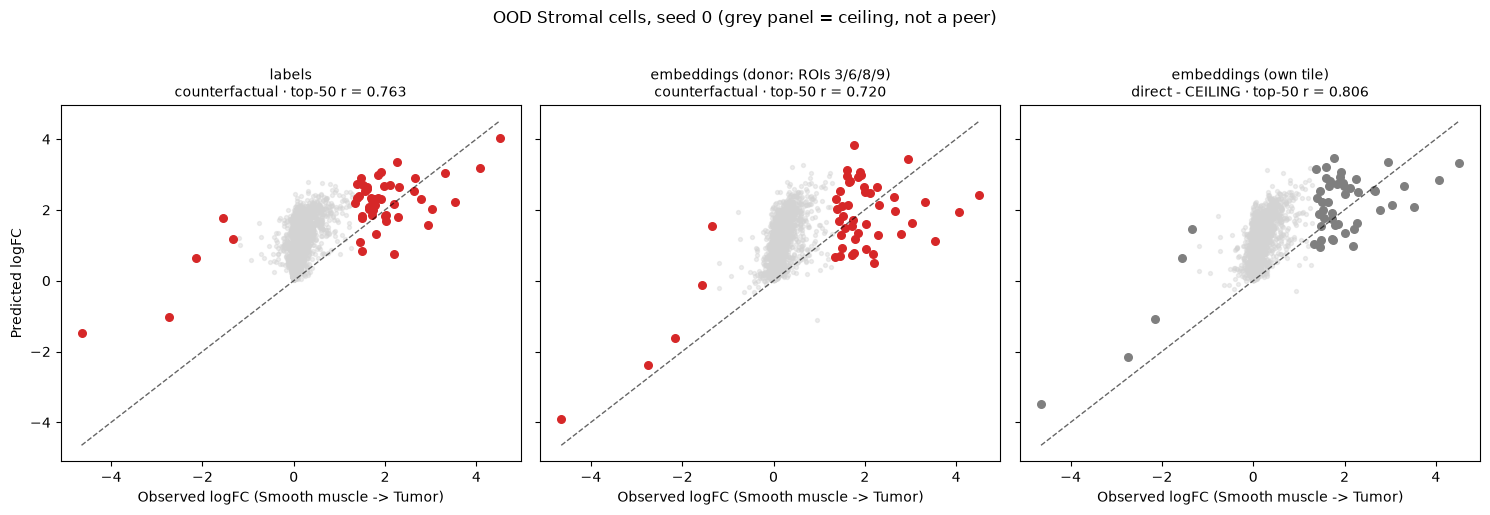

In [11]:
# Observed vs predicted logFC on the OOD held-out Stromal cells, seed 0, top-50 DE genes.
# Uses predicted_logfc_baseline="observed_control" to match the table above exactly.
import matplotlib.pyplot as plt

PANELS = ["labels", "emb_region", "emb_ceiling"]
ood = lambda a: a[(a.obs[LABELS_KEY].astype(str) == HOLDOUT_CT).values].copy()

fig, axes = plt.subplots(1, len(PANELS), figsize=(5 * len(PANELS), 5), sharex=True, sharey=True)
for ax, key in zip(axes, PANELS):
    display, kind = MODELS[key]
    pred = sc.read(os.path.join(PRED_DIR, f"{key}_seed0.h5ad"))
    obs_eff, pred_eff = get_perturbation_effects(
        ood(observed), ood(pred), pert_col=PERT_COL, control_label=CONTROL_LABEL,
        mode="logfc", predicted_logfc_baseline="observed_control",
    )
    o = obs_eff.loc[HOLDOUT_LABEL].values
    p = pred_eff.loc[HOLDOUT_LABEL].values
    deg = np.argsort(-np.abs(o))[:50]
    r = np.corrcoef(o[deg], p[deg])[0, 1]

    ax.scatter(o, p, s=8, color="lightgray", alpha=0.4)
    ax.scatter(o[deg], p[deg], s=30, color="#d62728" if kind.startswith("counter") else "#7f7f7f")
    lims = [min(o.min(), p.min()), max(o.max(), p.max())]
    ax.plot(lims, lims, "k--", lw=1, alpha=0.6)
    ax.set_xlabel(f"Observed logFC ({CONTROL_LABEL} -> {HOLDOUT_LABEL})")
    ax.set_title(f"{display}\n{kind} · top-50 r = {r:.3f}", fontsize=10)
axes[0].set_ylabel("Predicted logFC")
fig.suptitle(f"OOD {HOLDOUT_CT} cells, seed 0 (grey panel = ceiling, not a peer)", y=1.02)
plt.tight_layout()
plt.show()